$ \textbf{Aluna:}$ Alessandra da Silva Dias Malizia   
$ \textbf{Professor:}$ Cristiano Fernandes   
$ \textbf{Data:}$ 23 de Outubro de 2026

$ \textbf{Tese de Mestrado - 2026.1:}$ Modelagem de vazão de rios utilizando a distribuição de Harvey

In [2]:
import numpy as np
import pandas as pd
import datetime as dt
import harvey_gev as harvey

import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from scipy.stats import genextreme, uniform
import seaborn as sns
import statsmodels.api as sm
import importlib
from scipy.special import expit, gamma as gamma_func
# from scipy.constants import EulerGamma

In [3]:
gamma_E = 0.5772156649015329

In [4]:
# import inspect
# print(inspect.getsource(harvey.composite_score))

In [190]:
def salvar_resultados(
    result,
    arquivo="Resultados do Modelo.xlsx",
    observacoes=""
):
    # Data e horário da estimação/salvamento
    momento = datetime.now().strftime("%Y-%m-%d %H:%M:%S")

    # Parâmetros estimados, na ordem fixa original
    parametros = dict(
        zip(result.param_names, result.params_original)
    )

    # Linha com informações do ajuste
    nova_linha = {
        "Data e horário": momento,
        **parametros,
        "Log-verossimilhança": -result.fun,
        "Convergiu": result.success,
        "Mensagem": result.message,
        "Método": getattr(result, "method", ""),
        "Modo xi": result.xi_mode,
        "Modo varphi": result.varphi_mode,
        "Observações": observacoes
    }

    df_novo = pd.DataFrame([nova_linha])

    # Se existir, preserva as linhas anteriores
    if os.path.exists(arquivo):
        df_antigo = pd.read_excel(arquivo)

        # Preserva também colunas existentes de execuções anteriores
        df_final = pd.concat(
            [df_antigo, df_novo],
            ignore_index=True,
            sort=False
        )
    else:
        df_final = df_novo

    # Salva o arquivo Excel
    df_final.to_excel(arquivo, index=False)

    print(f"Resultados salvos em: {os.path.abspath(arquivo)}")
    print(f"Data e horário: {momento}")

    return df_final

# Dados BR

- Dados BR: Vazão do Rio Amazonas na estação 14990000 [https://www.snirh.gov.br/hidroweb/serieshistoricas]
- Dados Harvey: daily river Exe flow e level na base de Thorverton [https://environment.data.gov.uk/hydrology/station/3c4d4f78-2d0e-474a-b884-65a9daca18fb]  
  Grid Reference: SS9360201602
  River Name: River Exe  
  Catchment Area: 600.9 km²  
  Station Reference (Telemetry): 45118  
  Station ID (WISKI): SS90F011  
  API: https://environment.data.gov.uk/hydrology/doc/reference

In [4]:
path = r"C:\Users\aless\Documents\Mestrado\PUC\Tese\Dados\14990000_Cotas.csv"
data = pd.read_csv(path, skiprows=15, encoding='latin-1', sep=';') #, decimal=','

data = data[['Data', 'Maxima','Minima','Media']]
data['Data'] = pd.to_datetime(data['Data'], format='%d/%m/%Y')
data = data.set_index('Data').dropna(how='all')

data = data.resample('ME').mean()
data.at['2014-08-31','Media'] = 2546
data.at['2014-08-31','Maxima'] = 2906

series = data[['Maxima']].dropna()

print(data.shape)
# data.head(3)

(1347, 3)


In [4]:
# metadados
pd.set_option('display.max_colwidth', None)
pd.DataFrame(index=['Metadados'], data={
    'Fonte':'''Base de dados de vazão do Rio Amazonas da Agência Nacional de Águas (ANA)''', 
    'Unidade':'centímetros (cm)',
    'Período da série': '{} a {}'.format(series.index.min().strftime('%d/%m/%Y'), series.index.max().strftime('%d/%m/%Y')),
    'Observações': '{} meses'.format(series.shape[0])
}).T

,Metadados
Fonte,Base de dados de vazão do Rio Amazonas da Agência Nacional de Águas (ANA)
Unidade,centímetros (cm)
Período da série,30/09/1902 a 30/11/2014
Observações,1347 meses


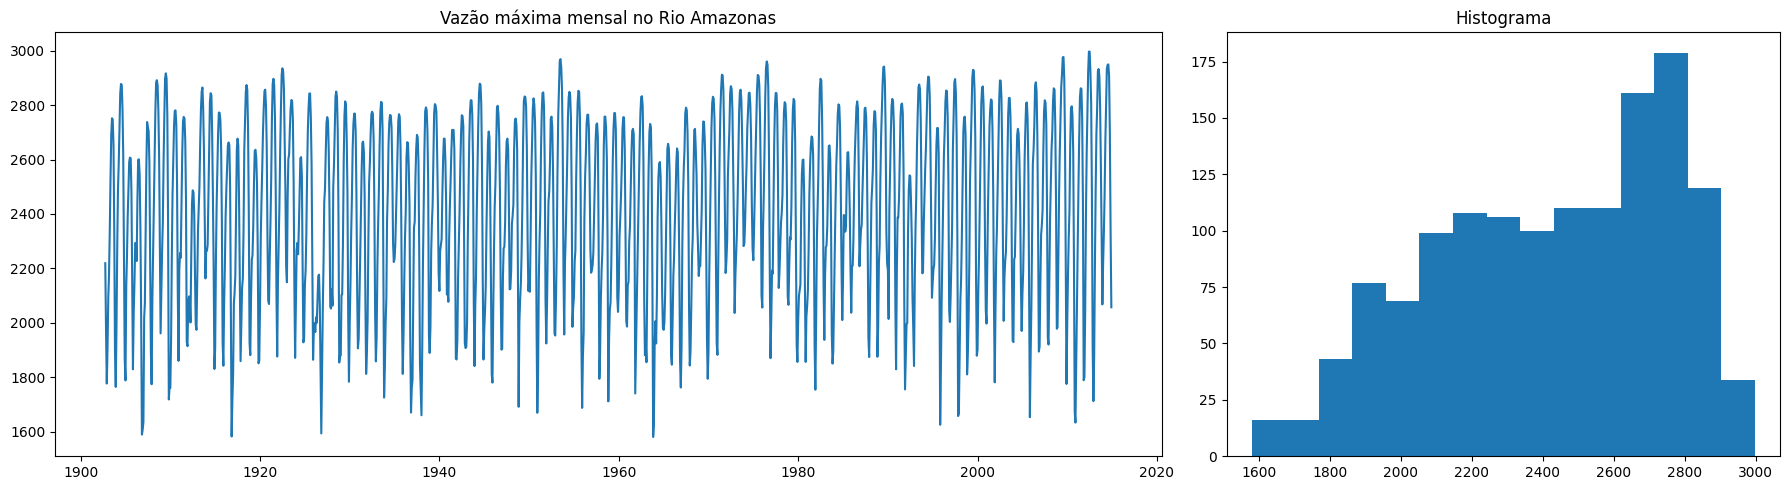

In [96]:
fig, ax = plt.subplots(1, 2, figsize=(18, 5), gridspec_kw={'width_ratios': [2, 1]})

ax[0].plot(series)
ax[0].set_title('Vazão máxima mensal no Rio Amazonas')

ax[1].hist(series, bins=15)
ax[1].set_title('Histograma')

plt.tight_layout()
plt.show()

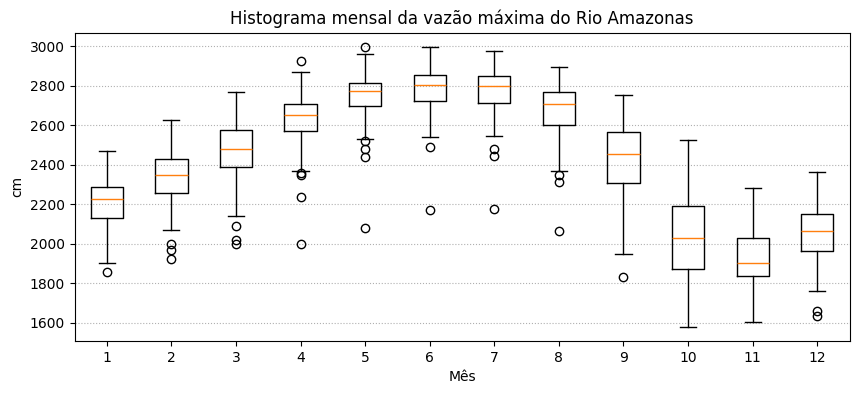

In [5]:
fig, ax = plt.subplots(figsize=(10,4))
plot_data = (series
    .pivot_table(columns=series.index.month, index=series.index.year, values='Maxima')
    .dropna()
)
ax.boxplot(plot_data)
ax.set_ylabel('cm')
ax.set_xlabel('Mês')
ax.grid(axis='y', linestyle=':')
ax.set_title('Histograma mensal da vazão máxima do Rio Amazonas')
plt.show()

## Modelagem

\begin{align}
y_t &= \mu_{t|t-1} + \gamma_t+\varphi\varepsilon_t, \qquad \text{com} \quad
\varepsilon_t \sim
\operatorname{GEV}(0,1,\xi_t) \quad \text{e} \quad
\varphi > 0 \\
\mu_{t+1|t} &= \mu(1-\phi) +\phi\mu_{t|t-1} +\kappa s_t \\
\gamma_t &=
\sum_{j=1}^{6}
\left(
\alpha_j
\cos\left(\frac{2\pi jt}{12}\right)
+
\beta_j
\sin\left(\frac{2\pi jt}{12}\right)
\right)
\end{align}

In [5]:
y = series['Maxima']
mu_init, alpha_init, beta_init = harvey.initial_seasonal_coefficients(y)

t = np.arange(1, len(series) + 1)
gamma_init = harvey.seasonal_component(t, alpha_init, beta_init)
residuos_init = y.to_numpy(dtype=float) - mu_init - gamma_init

# temporada de cheia de março a agosto
dummy = series.index.month.isin([3,4,5,6,7,8]).astype(int)
varphi_seca_init = np.std(residuos_init[dummy==0])
varphi_cheia_init = np.std(residuos_init[dummy==1])

print(f"mu inicial: {mu_init:.2f}")
print(f"varphi inicial: {varphi_seca_init:.2f}")
print(f"varphi inicial: {varphi_cheia_init:.2f}")

mu inicial: 2422.10
varphi inicial: 163.68
varphi inicial: 128.32


In [6]:
# parâmetros de otimização
init_params = [
    2422,     # mu
    164,     # varphi seca
    128,     # varphi cheia
    0.55,   # phi
    0.3,    # kappa
    0.1,    # xi seca
    None, # xi cheia
    *alpha_init,
    *beta_init
]
bounds = [
    (None, None),  # mu0
    (1e-8, None),  # varphi_seca
    (-0.999, 0.999),  # phi
    (1e-8, None),  # kappa
    (1e-8, 0.999),  # xi_seca
    (1e-8, None)  # varphi_cheia
    # ,(1e-8, 0.999),  # xi_cheia
]
bounds += [(None, None)] * 11

In [7]:
# estimação
start = dt.datetime.now()
print(start)
result = harvey.fit(y, dummy, init_params, bounds=bounds, xi_mode="constant", varphi_mode="seasonal")
end = dt.datetime.now()
print(f"Tempo de execução: {(end-start).seconds//60:02d}:{(end-start).seconds%60:02d}")

(
    mu_hat, varphi_seca_hat, varphi_cheia_hat, phi_hat, 
    kappa_hat, xi_seca_hat, xi_cheia_hat, alpha_hat, beta_hat 
) = harvey._unpack(result.x, xi_mode='constant', varphi_mode='seasonal')

2026-11-07 08:57:17.850031


C:\Users\aless\Desktop\Codes\masters\Tese\harvey_gev.py:347: RuntimeWarning: overflow encountered in exp
  * (1 - np.exp(-x[mask0]))


Tempo de execução: 00:51


In [9]:
print("Convergiu:", result.success)
print("Mensagem:", result.message)

print("\nEstimativas:")
print(f"mu: {mu_hat:.3f}")
print(f"varphi seca: {varphi_seca_hat:.3f}")
print(f"varphi cheia: {varphi_cheia_hat:.3f}")
print(f"phi: {phi_hat}")
print(f"kappa: {kappa_hat}")
print(f"xi seca: {xi_seca_hat}")
# print(f"xi cheia: {xi_cheia_hat}")

print("\nLog-likelihood =", -result.fun)

Convergiu: True
Mensagem: CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH

Estimativas:
mu: 2420.402
varphi seca: 138.890
varphi cheia: 61.687
phi: 0.7941385050374553
kappa: 1.0194787764803428
xi seca: 1e-08

Log-likelihood = -7982.832961015569


In [145]:
print("Convergiu:", result.success)
print("Mensagem:", result.message)

print("\nEstimativas:")
print(f"mu: {mu_hat:.3f}")
print(f"varphi seca: {varphi_seca_hat:.3f}")
print(f"varphi cheia: {varphi_cheia_hat:.3f}")
print(f"phi: {phi_hat}")
print(f"kappa: {kappa_hat}")
print(f"xi seca: {xi_seca_hat}")
# print(f"xi cheia: {xi_cheia_hat}")

print("\nLog-likelihood =", -result.fun)

Convergiu: True
Mensagem: CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH

Estimativas:
mu: 2278.331
varphi seca: 114.159
varphi cheia: 54.790
phi: 0.8672026552068328
kappa: 1.5947944316994016
xi seca: 1e-08

Log-likelihood = -7817.417770994423


In [10]:
result

         message: CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH
         success: True
          status: 0
             fun: 7982.832961015569
               x: [ 2.420e+03  1.389e+02 ...  2.520e+01 -1.239e+00]
             nit: 27
             jac: [-1.950e-01  8.322e-01 ... -1.191e-01 -3.960e-01]
            nfev: 810
            njev: 45
        hess_inv: <17x17 LbfgsInvHessProduct with dtype=float64>
 params_original: [ 2.420e+03  1.389e+02 ...  2.520e+01 -1.239e+00]
     param_names: ['mu0', 'varphi_seca', 'varphi_cheia', 'phi', 'kappa', 'xi_seca', 'xi_cheia', 'alpha1', 'alpha2', 'alpha3', 'alpha4', 'alpha5', 'alpha6', 'beta1', 'beta2', 'beta3', 'beta4', 'beta5']
         xi_mode: constant
     varphi_mode: seasonal

## Avaliação

In [11]:
mu_filtered, gamma_t, x, s, xi_t, varphi_t = harvey.filter(
    y, mu_hat, varphi_seca_hat, varphi_cheia_hat, phi_hat, kappa_hat, xi_seca_hat, xi_cheia_hat, dummy, alpha_hat, beta_hat
)
eta_t = mu_filtered + gamma_t
mean_cond = harvey.conditional_mean(mu_filtered, varphi_t, xi_t, gamma_t)

pit = harvey.cdf(y, mu_filtered, varphi_t, xi_t, gamma_t)

In [12]:
# regiões modificadas do score
mask_gumbel = (np.abs(xi_t) < 1e-6) & (x < 0)
mask_lower = np.zeros(len(x), dtype=bool)
mask_upper = np.zeros(len(x), dtype=bool)

c, d = {}, {}
c_t = np.full(len(x), np.nan)
d_t = np.full(len(x), np.nan)

for xi_value in np.unique(xi_t):
    if xi_value > 1e-6:
        c[xi_value] = harvey._find_c(xi_value)
        d[xi_value] = harvey._find_d(xi_value)

for i in range(len(x)):
    if xi_t[i] > 1e-6:
        c_t[i], d_t[i] = c[xi_value], d[xi_value]
        mask_lower[i] = x[i] <= c_t[i]
        mask_upper[i] = x[i] > d_t[i]

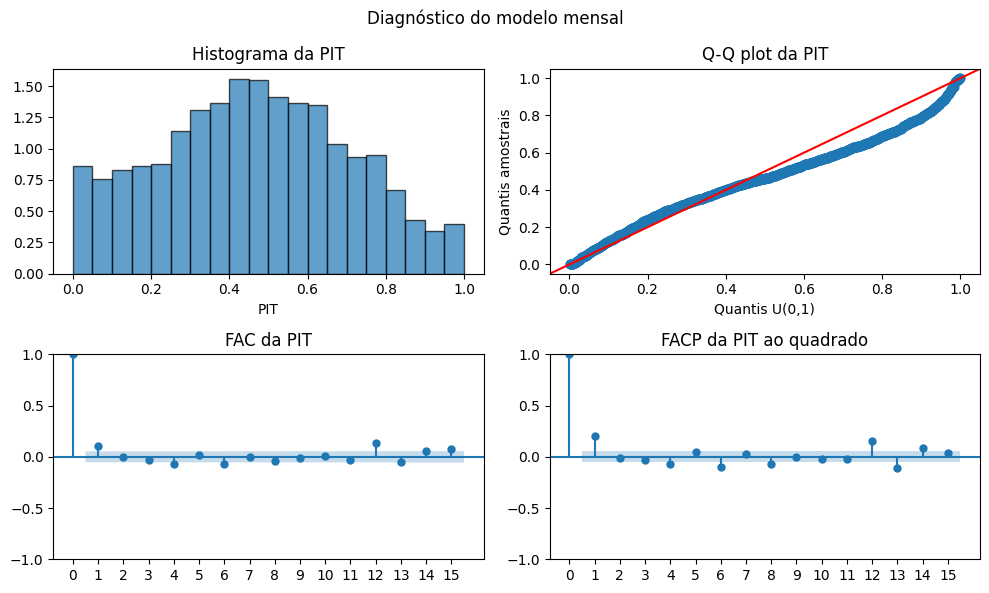

In [13]:
# pit
fig, ax = plt.subplots(2, 2, figsize=(10, 6))

# linha 1
ax[0,0].hist(pit, bins=20, density=True, edgecolor='black', alpha=0.7)
ax[0,0].set_title('Histograma da PIT')
ax[0,0].set_xlabel('PIT')

ax[0,1].set_title('Q-Q plot da PIT')
sm.qqplot(pit, dist=uniform, line='45', ax=ax[0,1], loc=0, scale=1)
ax[0,1].set_xlabel('Quantis U(0,1)')
ax[0,1].set_ylabel('Quantis amostrais')

# linha 2
lags = 15

plot_acf(pit, lags=lags, ax=ax[1,0], title='FAC da PIT')
ax[1,0].set_xticks(np.arange(lags+1))
ax[1,0].set_xticklabels(np.arange(lags+1))

plot_pacf(pit**2, lags=lags, ax=ax[1,1], title='FACP da PIT ao quadrado')
ax[1,1].set_xticks(np.arange(lags+1))
ax[1,1].set_xticklabels(np.arange(lags+1))

fig.suptitle('Diagnóstico do modelo mensal')
fig.tight_layout()
plt.show()

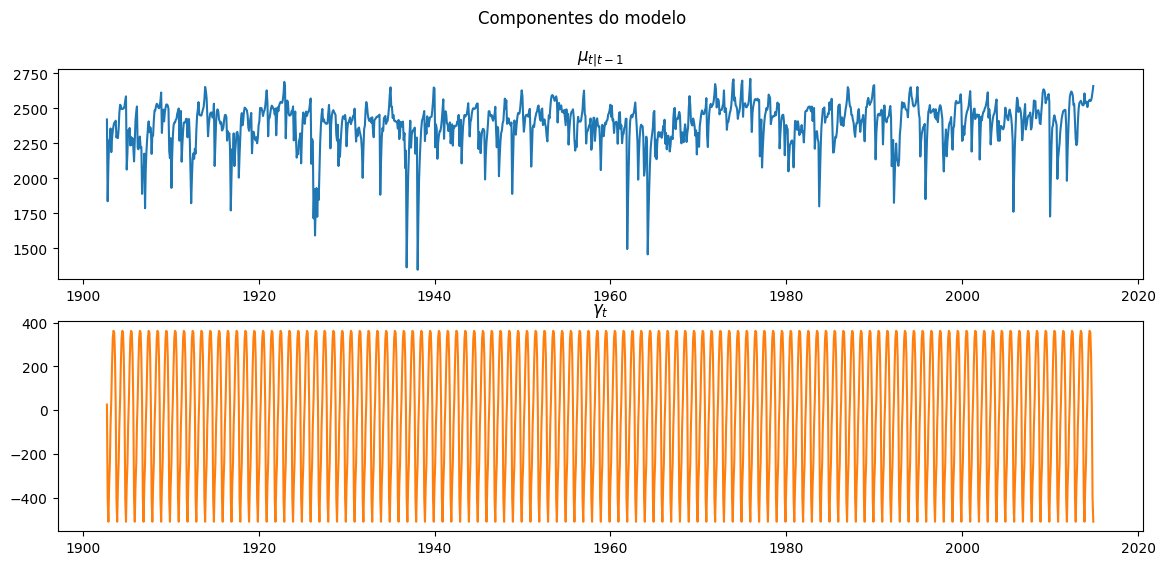

In [14]:
fig, ax = plt.subplots(2, 1, figsize=(14, 6))

ax[0].plot(series.index, mu_filtered, label=r"$\mu_{t|t-1}$")
ax[0].set_title(r"$\mu_{t|t-1}$")

ax[1].plot(series.index, gamma_t, label=r"$\gamma_t$", color='C1')
ax[1].set_title(r"$\gamma_t$")

fig.suptitle("Componentes do modelo")
# plt.legend()
plt.show()

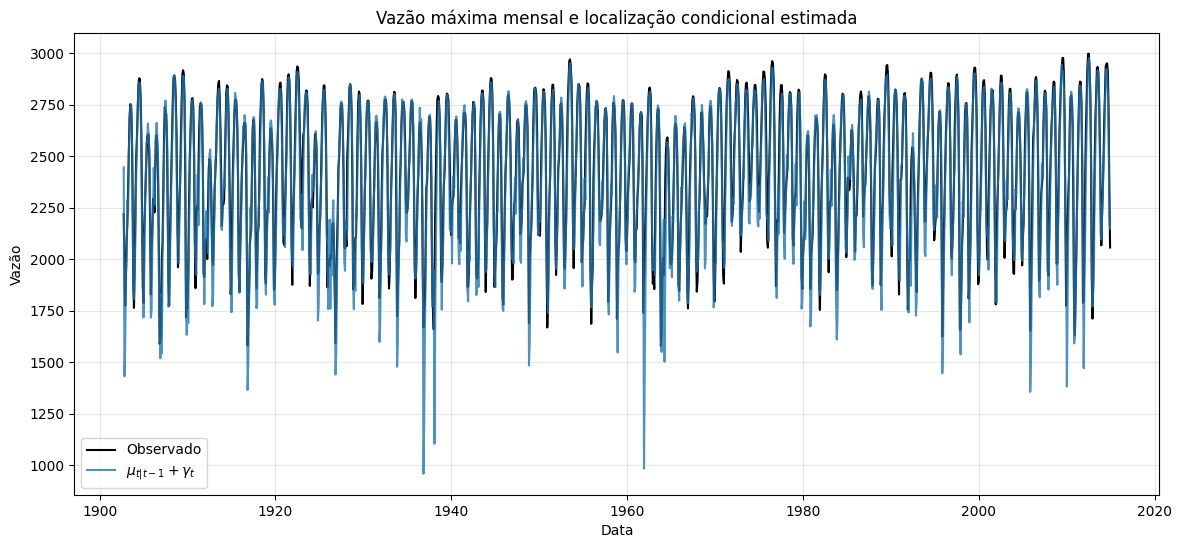

In [15]:
plt.figure(figsize=(14, 6))

plt.plot(series.index, series, label="Observado", color='black')
plt.plot(series.index, eta_t, label=r"$\mu_{t|t-1} + \gamma_t$", alpha=0.8)
# plt.plot(series.index, mean_cond, label=r"$E[y_t|\mathcal{F}_{t-1}]$")

plt.xlabel("Data")
plt.ylabel("Vazão")
plt.title("Vazão máxima mensal e localização condicional estimada")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

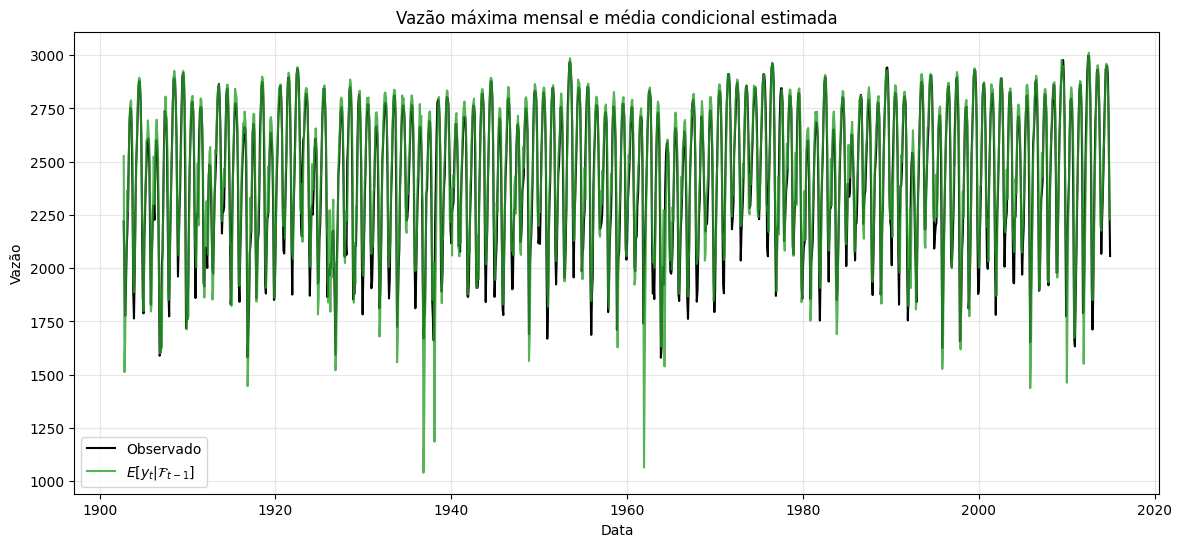

In [16]:
plt.figure(figsize=(14, 6))

plt.plot(series.index, series, label="Observado", color='black')
# plt.plot(series.index, eta_t, label=r"$\mu_{t|t-1} + \gamma_t$")
plt.plot(series.index, mean_cond, label=r"$E[y_t|\mathcal{F}_{t-1}]$", color='C2', alpha=0.8)

plt.xlabel("Data")
plt.ylabel("Vazão")
plt.title("Vazão máxima mensal e média condicional estimada")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

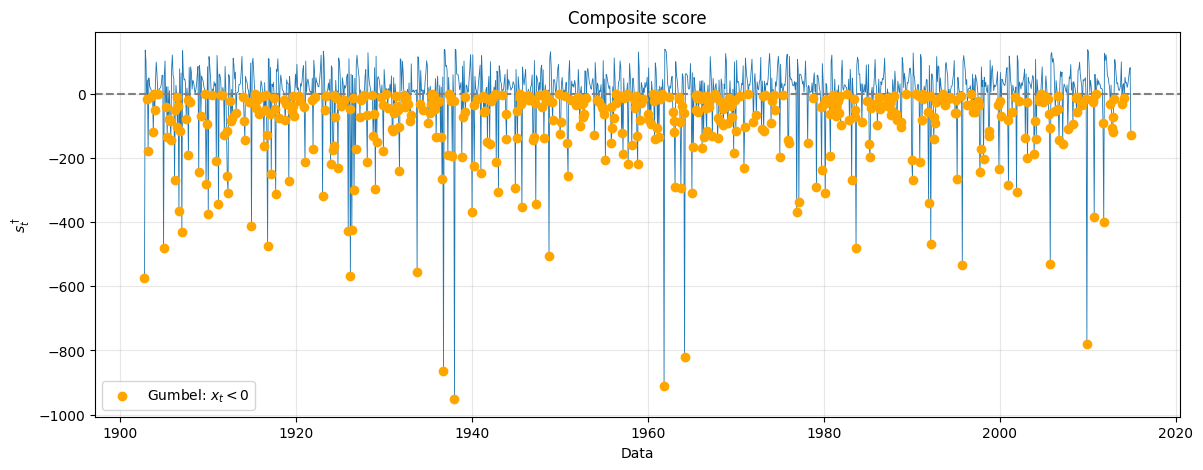

In [17]:
plt.figure(figsize=(14, 5))

plt.plot(series.index, s, linewidth=0.6)

plt.scatter(series.index[mask_gumbel], s[mask_gumbel], color="orange", zorder=3, label=r"Gumbel: $x_t<0$")
# plt.scatter(series.index[mask_lower], s[mask_lower], color="red", s=28, zorder=3, label=r"$\xi_t>0$: $x_t\leq c_t$")
# plt.scatter(series.index[mask_upper], s[mask_upper], color="purple", s=28, zorder=3, label=r"$\xi_t>0$: $x_t>d_t$")

plt.axhline(0, linestyle="--", color='gray')

plt.xlabel("Data")
plt.ylabel(r"$s_t^\dagger$")
plt.title("Composite score")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

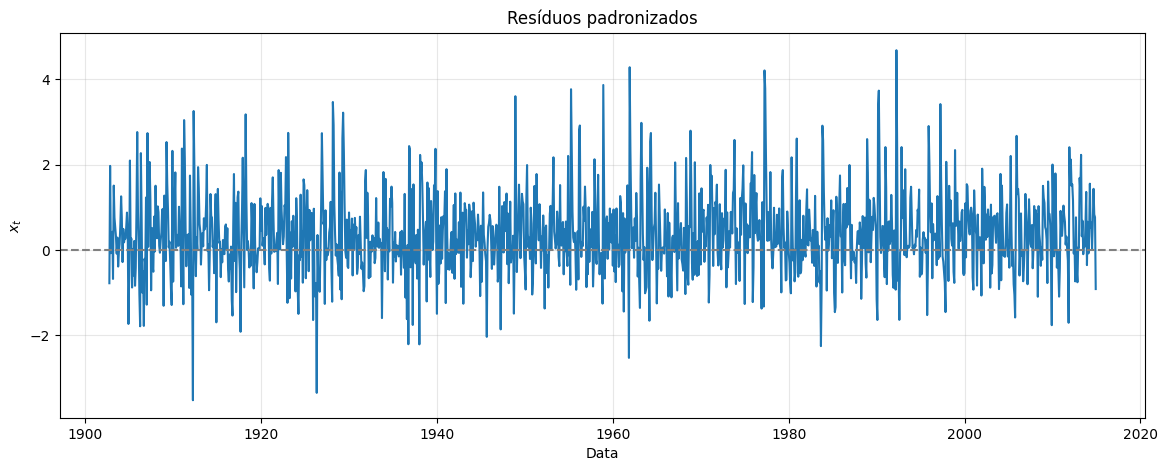

In [155]:
plt.figure(figsize=(14, 5))

plt.plot(series.index, x)
plt.axhline(0, linestyle="--", color='gray')

plt.xlabel("Data")
plt.ylabel(r"$x_t$")
plt.title("Resíduos padronizados")
plt.grid(alpha=0.3)

plt.show()

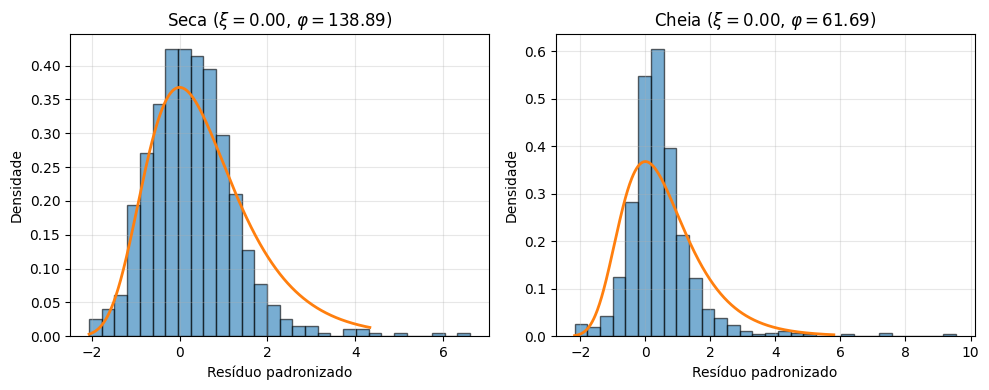

In [18]:
# Separar os resíduos por regime
regimes = [
    (x[dummy == 0], xi_seca_hat, varphi_seca_hat, "Seca"),
    (x[dummy == 1], xi_cheia_hat, varphi_cheia_hat, "Cheia")
]

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (x_regime, xi_hat, varphi_hat, nome) in zip(axes, regimes):
    # Grade da densidade teórica
    x_grid = np.linspace(np.min(x_regime), np.percentile(x_regime, 99.5), 500)

    # Histograma dos resíduos padronizados
    ax.hist(x_regime, bins=30, density=True, alpha=0.6, edgecolor="black")
    pdf = genextreme.pdf(x_grid, c=-xi_hat, loc=0, scale=1)
    ax.plot(x_grid, pdf, linewidth=2) # Densidade teórica

    ax.set_title(f"{nome} ($\\xi={xi_hat:.2f}$, $\\varphi={varphi_hat:.2f}$)")
    ax.set_xlabel("Resíduo padronizado")
    ax.set_ylabel("Densidade")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

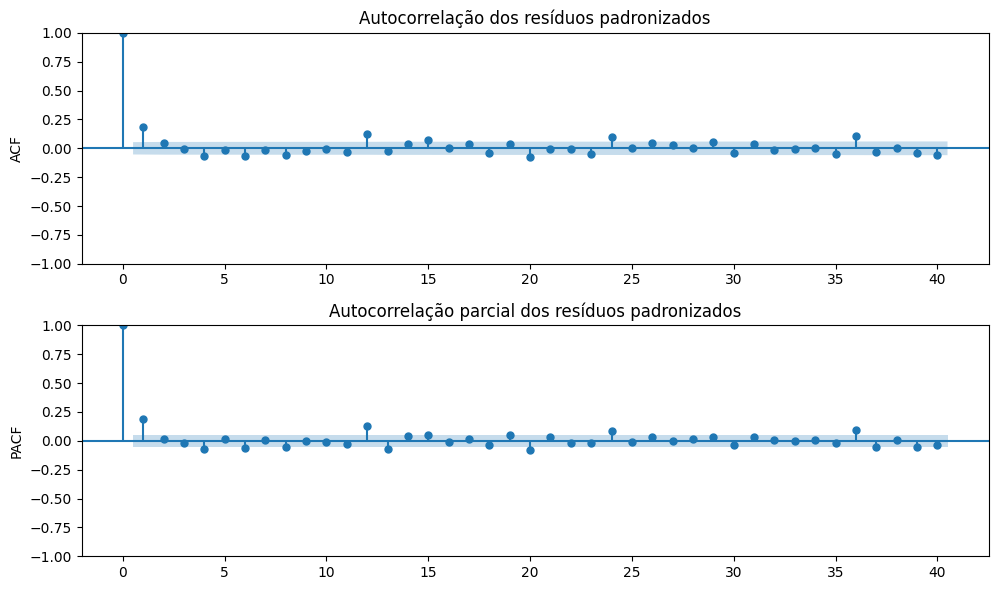

In [19]:
fig, ax = plt.subplots(2, 1, figsize=(10, 6))

plot_acf(x, lags=40, ax=ax[0])
plot_pacf(x, lags=40, ax=ax[1])
ax[0].set_title("Autocorrelação dos resíduos padronizados")
ax[0].set_ylabel("ACF")
ax[1].set_title("Autocorrelação parcial dos resíduos padronizados")
ax[1].set_ylabel("PACF")

plt.tight_layout()
plt.show()

## Score

In [160]:
def resumo(v):
    v = np.asarray(v, dtype=float)
    v = v[np.isfinite(v)]

    if len(v) == 0:
        return pd.Series({
            "n": 0, "Média": np.nan, "DP": np.nan,
            "Min": np.nan, "P1": np.nan, "P5": np.nan,
            "P95": np.nan, "P99": np.nan, "Max": np.nan
        })

    return pd.Series({
        "n": len(v),
        "Média": np.mean(v),
        "Desvio": np.std(v, ddof=1) if len(v) > 1 else np.nan,
        "Min": np.min(v),
        "Q1": np.quantile(v, 0.01),
        "Q5": np.quantile(v, 0.05),
        "Q95": np.quantile(v, 0.95),
        "Q99": np.quantile(v, 0.99),
        "Max": np.max(v)
    })

In [166]:
T = len(y)
t = np.arange(T)

df = pd.DataFrame({"t": t, "y": y, "x": x, "xi": xi_t, "s_composite": s})
df["c"] = np.nan
df["d"] = np.nan
df["regiao"] = "Gumbel superior"
df["score_modificado"] = False
df["estacao"] = np.where(dummy == 1, "Cheia", "Seca")

# Caso Gumbel: xi aproximadamente zero
gumbel = np.abs(xi_t) < 1e-6
gumbel_lower = gumbel & (x < 0)
gumbel_upper = gumbel & (x >= 0)

df.loc[gumbel_lower, "regiao"] = "Gumbel inferior"
df.loc[gumbel_upper, "regiao"] = "Gumbel superior"
df.loc[gumbel_lower, "score_modificado"] = True

# Casos xi diferente de zero
for xi_value in np.unique(xi_t[~gumbel]):
    mask = np.isclose(xi_t, xi_value, rtol=0, atol=1e-12)

    c, d = harvey._find_c(xi_value), harvey._find_d(xi_value)
    df.loc[mask, "c"] = c
    df.loc[mask, "d"] = d

    lower = mask & (x <= c)
    middle = mask & (x > c) & (x <= d)
    upper = mask & (x > d)

    df.loc[lower, "regiao"] = "Inferior"
    df.loc[middle, "regiao"] = "Intermediária"
    df.loc[upper, "regiao"] = "Superior"
    df.loc[lower | upper, "score_modificado"] = True

In [167]:
score_original = np.full(T, np.nan)

for xi_value in np.unique(xi_t):

    mask = np.isclose(xi_t, xi_value, rtol=0, atol=1e-12)
    I = harvey.fisher_information(xi_value, varphi_hat)
    score_bruto = harvey.score(y[mask], xi_value, mu_filtered[mask], gamma_t[mask], varphi_hat)
    score_original[mask] = np.asarray(score_bruto).reshape(-1) / I

df["s_original"] = score_original
df["diferenca"] = df["s_composite"] - df["s_original"]

df.head(3)

,t,y,x,xi,s_composite,c,d,regiao,score_modificado,estacao,s_original,diferenca
Data,,,,,,,,,,,,
1902-09-30,0,2219.0,-0.780704,1.000000e-08,-89.124594,NaN,NaN,Gumbel inferior,True,Seca,-223.919262,134.794668
1902-10-31,1,1970.0,1.971040,1.000000e-08,98.255468,NaN,NaN,Gumbel superior,False,Seca,53.887940,44.367528
1902-11-30,2,1776.5,-0.075860,1.000000e-08,-8.660168,NaN,NaN,Gumbel inferior,True,Seca,-9.382121,0.721952


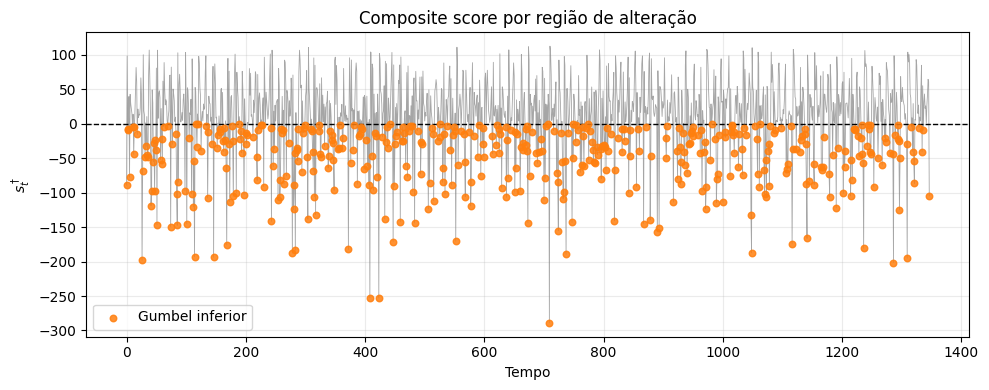

In [172]:
cores = {
    "Gumbel inferior": "tab:orange",
    "Gumbel superior": "yellow"
}

fig, ax = plt.subplots(figsize=(10, 4))

ax.plot(np.arange(len(s)), s, linewidth=0.6, color='gray', alpha=0.7)
for regiao, grupo in df.groupby("regiao", sort=False):
    if regiao == 'Gumbel inferior':
        ax.scatter(grupo["t"], grupo["s_composite"], s=22, color=cores[regiao], label=regiao, alpha=0.85, zorder=3)

ax.axhline(0, color="black", linestyle="--", linewidth=1)
ax.set(title="Composite score por região de alteração", xlabel="Tempo", ylabel=r"$s_t^\dagger$")
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

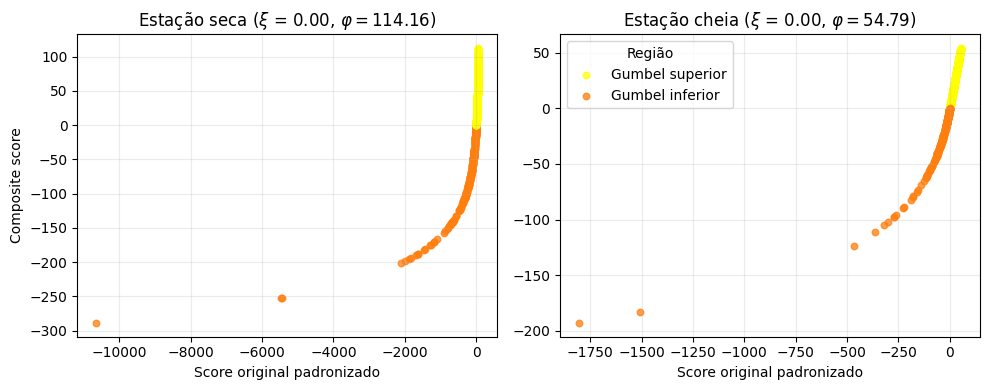

In [177]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, estacao in zip(axes, ["Seca", "Cheia"]):
    df_estacao = df[df["estacao"] == estacao]
    xi = df_estacao['xi'].iloc[0]
    varphi_hat = varphi_seca_hat if estacao == "Seca" else varphi_cheia_hat

    for regiao, grupo in df_estacao.groupby("regiao", sort=False):
        ax.scatter(grupo["s_original"], grupo["s_composite"], s=22, color=cores[regiao], label=regiao, alpha=0.75)

    ax.set(title=f"Estação {estacao.lower()} ($\\xi$ = {xi:.2f}, $\\varphi={varphi_hat:.2f}$)", xlabel="Score original padronizado")
    ax.grid(alpha=0.25)

axes[0].set_ylabel("Composite score")
axes[1].legend(title="Região")

plt.tight_layout()
plt.show()

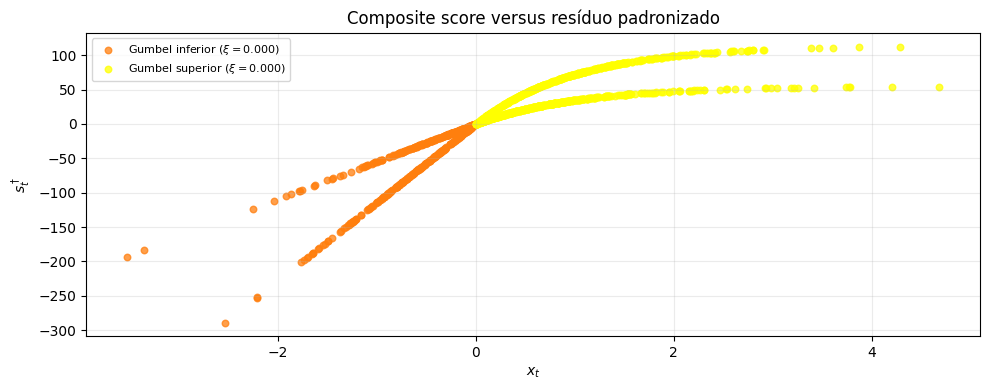

In [176]:
fig, ax = plt.subplots(figsize=(10, 4))

for xi_value in np.unique(xi_t):

    mask = np.isclose(xi_t, xi_value, rtol=0, atol=1e-12)

    for nome in ["Gumbel inferior", "Gumbel superior"]:
        m = mask & (df["regiao"].to_numpy() == nome)
        ax.scatter(x[m], s[m], color=cores[nome], s=22, alpha=0.75, label=f"{nome} ($\\xi={xi_value:.3f}$)")

ax.set(title="Composite score versus resíduo padronizado", xlabel=r"$x_t$", ylabel=r"$s_t^\dagger$")
ax.grid(alpha=0.25)

# Remove rótulos duplicados da legenda
handles, labels = ax.get_legend_handles_labels()
by_label = dict(zip(labels, handles))
ax.legend(by_label.values(), by_label.keys(), fontsize=8)

plt.tight_layout()
plt.show()

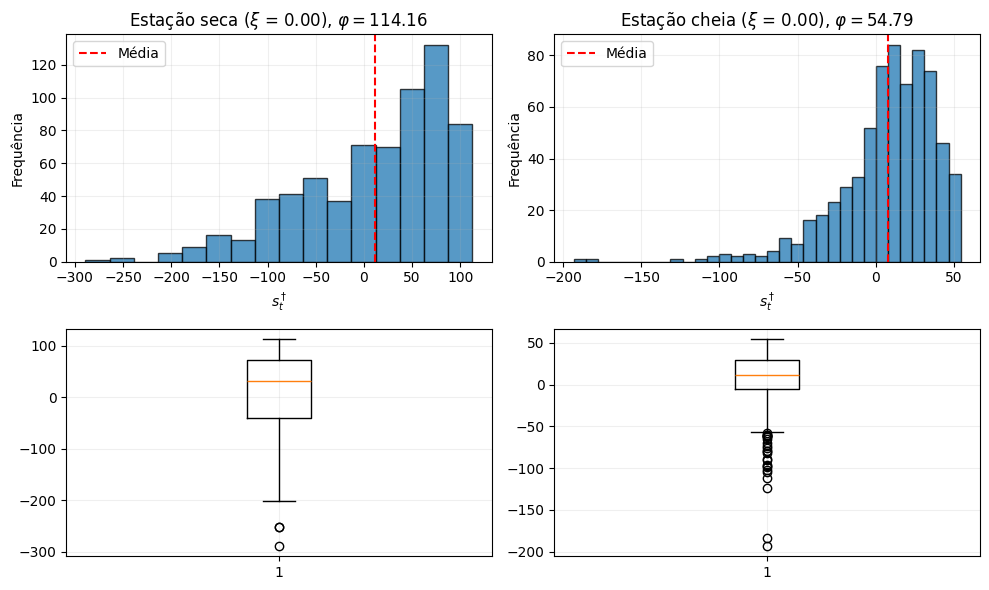

In [178]:
fig, axes = plt.subplots(2, 2, figsize=(10, 6))

for j, estacao in enumerate(["Seca", "Cheia"]):
    valores = df.loc[df["estacao"] == estacao, "s_composite"].dropna()
    xi = df.loc[df["estacao"] == estacao, 'xi'].iloc[0]
    varphi_hat = varphi_seca_hat if estacao == "Seca" else varphi_cheia_hat

    axes[0, j].hist(valores, bins="auto", edgecolor="black", alpha=0.75)
    axes[0, j].axvline(valores.mean(), color="red", linestyle="--", label="Média")
    axes[0, j].set(title=f"Estação {estacao.lower()} ($\\xi$ = {xi:.2f}), $\\varphi={varphi_hat:.2f}$", xlabel=r"$s_t^\dagger$", ylabel="Frequência")
    axes[0, j].legend()
    axes[0, j].grid(alpha=0.2)
    
    axes[1, j].boxplot(valores, vert=True)
    axes[1, j].grid(alpha=0.2)

plt.tight_layout()
plt.show()

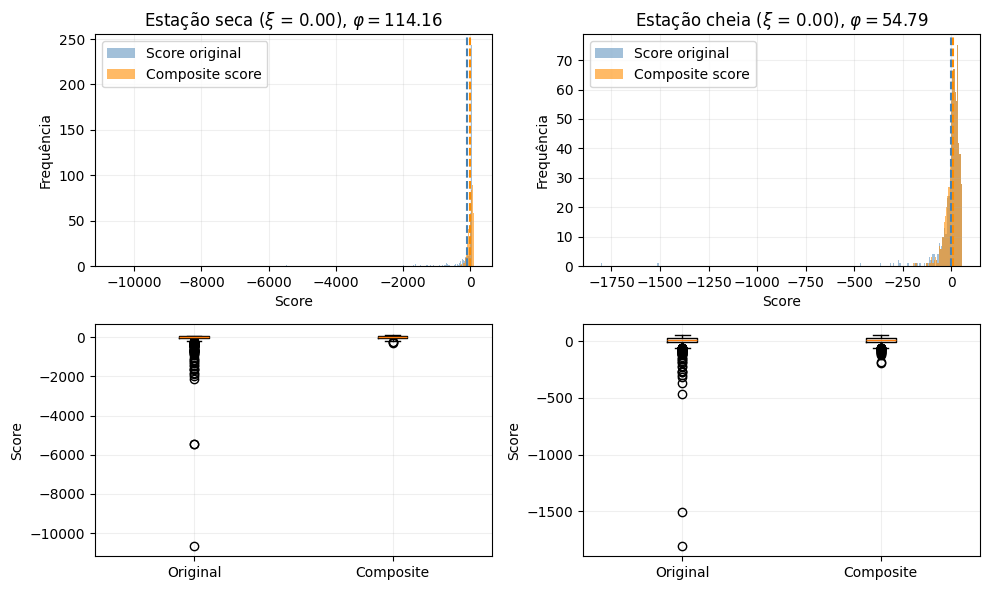

In [179]:
fig, axes = plt.subplots(2, 2, figsize=(10, 6))

for j, estacao in enumerate(["Seca", "Cheia"]):
    df_estacao = df[df["estacao"] == estacao]
    composite = df_estacao["s_composite"].dropna()
    original = df_estacao["s_original"].dropna()
    xi = df_estacao["xi"].iloc[0]
    varphi_hat = varphi_seca_hat if estacao == "Seca" else varphi_cheia_hat

    # Histograma sobreposto
    bins = np.histogram_bin_edges(
        np.concatenate([composite.to_numpy(), original.to_numpy()]),
        bins="auto"
    )
    axes[0, j].hist(original, bins=bins, color="steelblue", alpha=0.5, label="Score original")
    axes[0, j].hist(composite, bins=bins, color="darkorange", alpha=0.6, label="Composite score")
    axes[0, j].axvline(original.mean(), color="steelblue", linestyle="--")
    axes[0, j].axvline(composite.mean(), color="darkorange", linestyle="--")
    axes[0, j].set(title=f"Estação {estacao.lower()} ($\\xi$ = {xi:.2f}), $\\varphi={varphi_hat:.2f}$", xlabel="Score", ylabel="Frequência")
    axes[0, j].legend()
    axes[0, j].grid(alpha=0.2)

    # Boxplots lado a lado
    axes[1, j].boxplot(
        [original, composite],
        tick_labels=["Original", "Composite"],
        showfliers=True
    )
    axes[1, j].set_ylabel("Score")
    axes[1, j].grid(alpha=0.2)

plt.tight_layout()
plt.show()

In [180]:
print("\nEstatísticas gerais:")
resumo(df["s_composite"]).to_frame("Composite score").round(2).T


Estatísticas gerais:


,n,Média,Desvio,Min,Q1,Q5,Q95,Q99,Max
Composite score,1347.0,9.49,57.63,-288.97,-178.48,-101.6,92.18,106.06,112.59


In [181]:
frequencias = (
    df.groupby("estacao")
      .agg(
          n=("s_composite", "size"),
          media=("s_composite", "mean"),
          minimo=("s_composite", "min"),
          maximo=("s_composite", "max")
      )
)

frequencias["proporcao_%"] = 100 * frequencias["n"] / len(df)
print(
    "\nProporção total com score modificado:",
    round(100 * df["score_modificado"].mean(), 2), "%"
)
frequencias.round(2)


Proporção total com score modificado: 33.63 %


,n,media,minimo,maximo,proporcao_%
estacao,,,,,
Cheia,672,7.81,-193.09,54.28,49.89
Seca,675,11.16,-288.97,112.59,50.11


# Dados Harvey

- Dados Harvey: daily river Exe flow e level na base de Thorverton [https://environment.data.gov.uk/hydrology/station/3c4d4f78-2d0e-474a-b884-65a9daca18fb]  
  Grid Reference: SS9360201602
  River Name: River Exe  
  Catchment Area: 600.9 km²  
  Station Reference (Telemetry): 45118  
  Station ID (WISKI): SS90F011  
  API: https://environment.data.gov.uk/hydrology/doc/reference

In [3]:
path = r"C:\Users\aless\Documents\Mestrado\PUC\Tese\Dados\Thorverton-flow-daily-Qualified.csv"

data = pd.read_csv(path)

data['date'] = pd.to_datetime(data['date'])

data = data.set_index('date').dropna(how='all')
series = data.loc['1965':'2026-01',['value']].resample('ME').max()

print(series.shape)
# series.head(3)

(733, 1)


In [4]:
# metadados
pd.set_option('display.max_colwidth', None)
pd.DataFrame(index=['Metadados'], data={
    'Fonte':'''Base de dados de vazão do Rio Amazonas da Agência Nacional de Águas (ANA)''', 
    'Unidade':'centímetros (cm)',
    'Período da série': '{} a {}'.format(series.index.min().strftime('%d/%m/%Y'), series.index.max().strftime('%d/%m/%Y')),
    'Observações': '{} meses'.format(series.shape[0])
}).T

,Metadados
Fonte,Base de dados de vazão do Rio Amazonas da Agência Nacional de Águas (ANA)
Unidade,centímetros (cm)
Período da série,31/01/1965 a 31/01/2026
Observações,733 meses


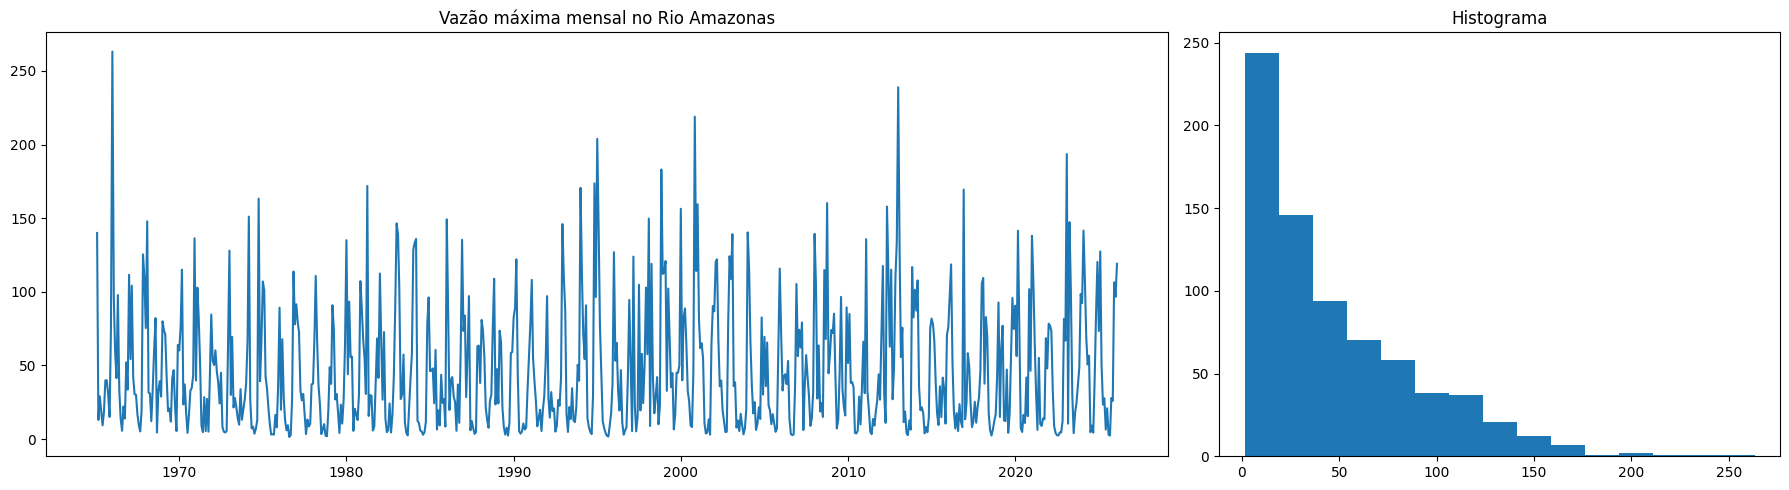

In [46]:
fig, ax = plt.subplots(1, 2, figsize=(18, 5), gridspec_kw={'width_ratios': [2, 1]})

ax[0].plot(series)
ax[0].set_title('Vazão máxima mensal no Rio Amazonas')

ax[1].hist(series, bins=15)
ax[1].set_title('Histograma')

plt.tight_layout()
plt.show()

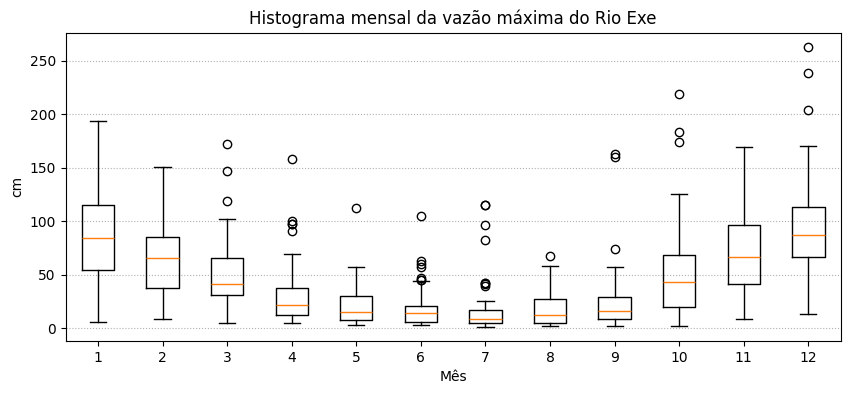

In [47]:
fig, ax = plt.subplots(figsize=(10,4))
plot_data = (series
    .pivot_table(columns=series.index.month, index=series.index.year, values='value')
    .dropna()
)
ax.boxplot(plot_data)
ax.set_ylabel('cm')
ax.set_xlabel('Mês')
ax.grid(axis='y', linestyle=':')
ax.set_title('Histograma mensal da vazão máxima do Rio Exe')
plt.show()

## Modelagem

In [1]:
importlib.reload(harvey)

NameError: name 'importlib' is not defined

In [5]:
y = series['value']
mu_init, alpha_init, beta_init = harvey.initial_seasonal_coefficients(y)

t = np.arange(1, len(y) + 1)
gamma_init = harvey.seasonal_component(t, alpha_init, beta_init)
residuos_init = y.to_numpy(dtype=float) - mu_init - gamma_init
# varphi_init = np.std(residuos_init)

# temporada de cheia (verão) de abril a setembro
dummy = series.index.month.isin([4,5,6,7,8,9]).astype(int)
varphi_seca_init = np.std(residuos_init[dummy == 0])
varphi_cheia_init = np.std(residuos_init[dummy == 1])

print(f"mu inicial: {mu_init:.2f}")
print(f"varphi seca inicial: {varphi_seca_init:.2f}")
print(f"varphi cheia inicial: {varphi_cheia_init:.2f}")

mu inicial: 46.40
varphi seca inicial: 39.53
varphi cheia inicial: 23.17


In [123]:
# Ordem de otimização, não a ordem de init_params
bounds = [
    (None, None),  # mu0
    (1e-8, None),  # varphi_seca
    (1e-8, 0.999),  # phi
    (1e-8, None),  # kappa
    (1e-8, 0.999),  # xi_seca
    (1e-8, None),  # varphi_cheia
    (1e-8, 0.999),  # xi_cheia
]
bounds += [(None, None)] * 11

init_params = [
    46,     # mu
    40,     # varphi seca
    23,     # varphi cheia
    0.55,   # phi
    0.3,    # kappa
    0.1,    # xi seca
    0.3, # xi cheia
    *alpha_init,
    *beta_init
]
start = dt.datetime.now()
print(start)
result = harvey.fit(y, dummy, init_params, bounds=bounds, xi_mode="seasonal", varphi_mode="seasonal")
end = dt.datetime.now()
print(f"Tempo de execução: {(end-start).seconds//60:02d}:{(end-start).seconds%60:02d}")

(
    mu_hat, varphi_seca_hat, varphi_cheia_hat, phi_hat, 
    kappa_hat, xi_seca_hat, xi_cheia_hat, alpha_hat, beta_hat 
) = harvey._unpack(result.x, xi_mode='seasonal', varphi_mode='seasonal')

2026-11-07 07:25:30.252703
Tempo de execução: 00:10


In [124]:
print("Convergiu:", result.success)
print("Mensagem:", result.message)

print("\nEstimativas:")
print(f"mu: {mu_hat:.3f}")
print(f"varphi seca: {varphi_seca_hat:.3f}")
print(f"varphi cheia: {varphi_cheia_hat:.3f}")
print(f"phi: {phi_hat}")
print(f"kappa: {kappa_hat}")
print(f"xi seca: {xi_seca_hat}")
print(f"xi cheia: {xi_cheia_hat}")

print("\nLog-likelihood =", -result.fun)

Convergiu: True
Mensagem: CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH

Estimativas:
mu: 44.013
varphi seca: 39.831
varphi cheia: 19.029
phi: 0.7655266617397549
kappa: 0.1559955537490872
xi seca: 0.05199852111646131
xi cheia: 0.6355303709489726

Log-likelihood = -3439.2098433845813


In [106]:
result

         message: CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH
         success: True
          status: 0
             fun: 3440.16389544573
               x: [ 4.362e+01  3.999e+01 ...  4.038e-01  3.111e+00]
             nit: 2
             jac: [ 7.368e+00  1.566e+00 ...  3.005e+00 -5.704e+00]
            nfev: 95
            njev: 5
        hess_inv: <18x18 LbfgsInvHessProduct with dtype=float64>
 params_original: [ 4.362e+01  3.999e+01 ...  4.038e-01  3.111e+00]
     param_names: ['mu0', 'varphi_seca', 'varphi_cheia', 'phi', 'kappa', 'xi_seca', 'xi_cheia', 'alpha1', 'alpha2', 'alpha3', 'alpha4', 'alpha5', 'alpha6', 'beta1', 'beta2', 'beta3', 'beta4', 'beta5']
         xi_mode: seasonal
     varphi_mode: seasonal

In [ ]:
# salvar_resultados(result, observacoes="Máximos mensais do nível do rio Amazonas")

# xi_seca_harvey = 0.6
# xi_cheia_harvey = 0
# phi_seca_harvey = 8.24
# phi_cheia_harvey = 32.13

# for xi, phi in [(xi_cheia_harvey, phi_cheia_harvey), (xi_seca_harvey, phi_seca_harvey)]:
#     if xi!=0:
#         delta = (
#             gamma_func(1-xi) - 1
#         ) * phi / xi
#     else:
#         delta = 0.577*phi
#     print(delta)

In [130]:
np.min(xi_t)

0.05199852111646131

## Avaliação

In [132]:
mu_filtered, gamma_t, x, s, xi_t, varphi_t = harvey.filter(
    y, mu_hat, varphi_seca_hat, varphi_cheia_hat, phi_hat, kappa_hat, xi_seca_hat, xi_cheia_hat, dummy, alpha_hat, beta_hat
)
eta_t = mu_filtered + gamma_t
mean_cond = harvey.conditional_mean(mu_filtered, varphi_t, xi_t, gamma_t)
mode_cond = harvey.conditional_mode(mu_filtered, varphi_t, xi_t, gamma_t)
median_cond = harvey.conditional_median(mu_filtered, varphi_t, xi_t, gamma_t)

pit = harvey.cdf(y, mu_filtered, varphi_t, xi_t, gamma_t)

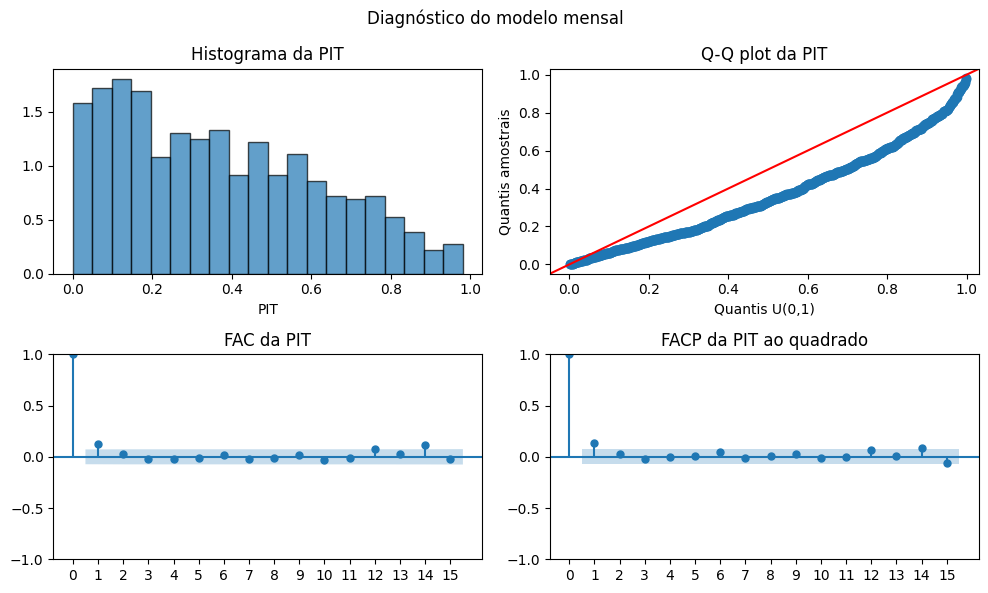

In [126]:
# pit
fig, ax = plt.subplots(2, 2, figsize=(10, 6))

# linha 1
ax[0,0].hist(pit, bins=20, density=True, edgecolor='black', alpha=0.7)
ax[0,0].set_title('Histograma da PIT')
ax[0,0].set_xlabel('PIT')

ax[0,1].set_title('Q-Q plot da PIT')
sm.qqplot(pit, dist=uniform, line='45', ax=ax[0,1], loc=0, scale=1)
ax[0,1].set_xlabel('Quantis U(0,1)')
ax[0,1].set_ylabel('Quantis amostrais')

# linha 2
lags = 15

plot_acf(pit, lags=lags, ax=ax[1,0], title='FAC da PIT')
ax[1,0].set_xticks(np.arange(lags+1))
ax[1,0].set_xticklabels(np.arange(lags+1))

plot_pacf(pit**2, lags=lags, ax=ax[1,1], title='FACP da PIT ao quadrado')
ax[1,1].set_xticks(np.arange(lags+1))
ax[1,1].set_xticklabels(np.arange(lags+1))

fig.suptitle('Diagnóstico do modelo mensal')
fig.tight_layout()
plt.show()

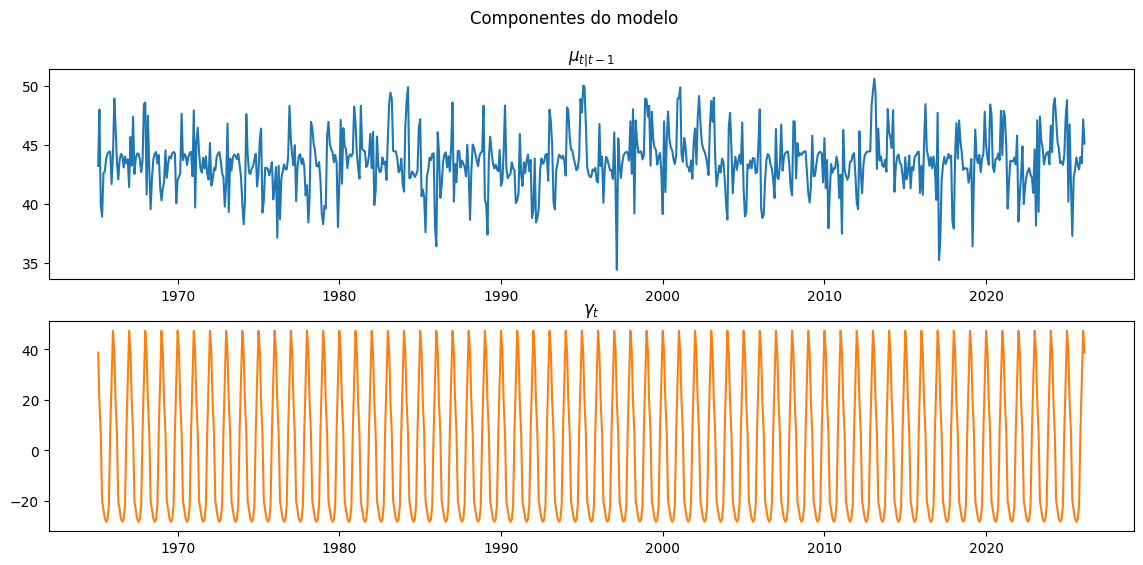

In [43]:
fig, ax = plt.subplots(2, 1, figsize=(14, 6))

ax[0].plot(series.index, mu_filtered, label=r"$\mu_{t|t-1}$")
ax[0].set_title(r"$\mu_{t|t-1}$")

ax[1].plot(series.index, gamma_t, label=r"$\gamma_t$", color='C1')
ax[1].set_title(r"$\gamma_t$")

fig.suptitle("Componentes do modelo")
# plt.legend()
plt.show()

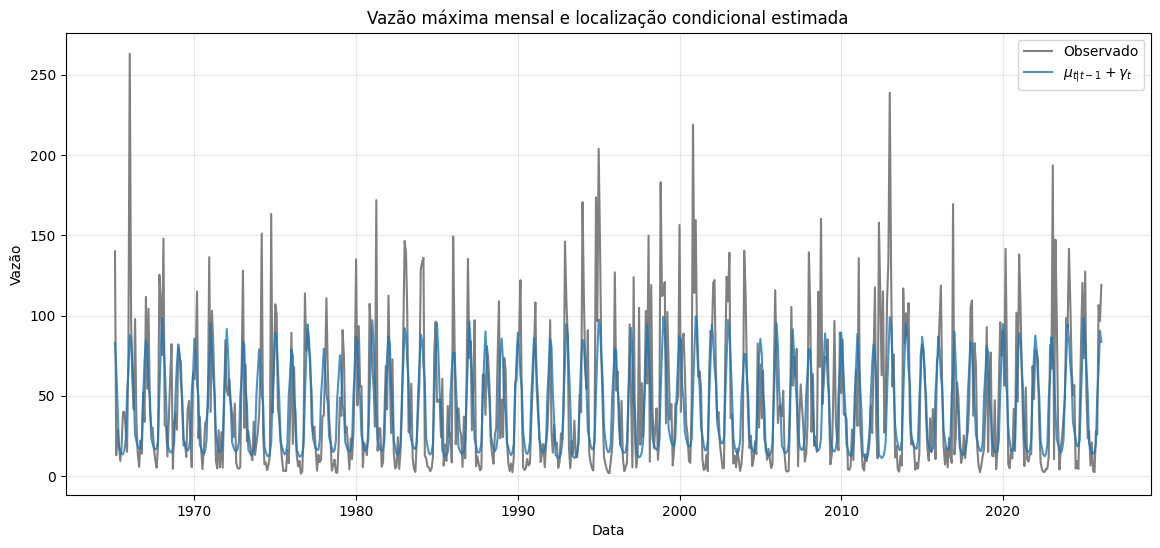

In [127]:
plt.figure(figsize=(14, 6))

plt.plot(series.index, series, label="Observado", color='gray')
plt.plot(series.index, eta_t, label=r"$\mu_{t|t-1} + \gamma_t$", alpha=0.8)
# plt.plot(series.index, mean_cond, label=r"$E[y_t|\mathcal{F}_{t-1}]$")

plt.xlabel("Data")
plt.ylabel("Vazão")
plt.title("Vazão máxima mensal e localização condicional estimada")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [157]:
def get_shifts(xi, varphi):
    # gumbel
    if np.abs(xi) < 1e-6:
        shift_mean = varphi * 0.5772156649015329
        shift_median = -varphi * np.log(-np.log(0.5))
        shift_mode = 0.0
        
    # frechet 
    else:
        shift_mean = (
            varphi
            * (gamma_func(1 - xi) - 1)
            / xi
        )
        shift_median = (
            varphi
            * (np.exp(-xi * np.log(-np.log(0.5))) - 1)
            / xi
        )
        shift_mode = (
            varphi
            * (np.exp(-xi * np.log1p(xi)) - 1)
            / xi
        )
    
    return shift_mean, shift_median, shift_mode

In [160]:
df_shifts = pd.DataFrame(columns=['estação','modelo','xi','varphi','shift_mean','shift_median','shift_mode'])

for xi_value in np.unique(xi_t):
    mask = np.isclose(xi_t, xi_value, rtol=0, atol=1e-12)
    estacao = 'seca' if np.all(dummy[mask] == 0) else 'cheia'
    
    varphi_value = varphi_seca_hat if estacao == 'seca' else varphi_cheia_hat
    shift_mean, shift_median, shift_mode = get_shifts(xi_value, varphi_value)
    df_shifts.loc[len(df_shifts)] = [estacao, 'estimado', xi_value, varphi_value, shift_mean, shift_median, shift_mode]

# Estimativas de Harvey
parametros_harvey = {
    "cheia": {"xi": 0.0, "varphi": 32.13},
    "seca": {"xi": 0.60, "varphi": 8.24}
}
for estacao, params in parametros_harvey.items():
    shift_mean, shift_median, shift_mode = get_shifts(params["xi"], params["varphi"])
    df_shifts.loc[len(df_shifts)] = [estacao, 'Harvey', params["xi"], params["varphi"], shift_mean, shift_median, shift_mode]
    
df_shifts.round(3)

,estação,modelo,xi,varphi,shift_mean,shift_median,shift_mode
0,seca,estimado,0.052,39.831,25.143,14.739,-2.016
1,cheia,estimado,0.636,19.029,43.156,7.854,-8.039
2,cheia,Harvey,0.000,32.130,18.546,11.776,0.000
3,seca,Harvey,0.600,8.240,16.729,3.378,-3.375


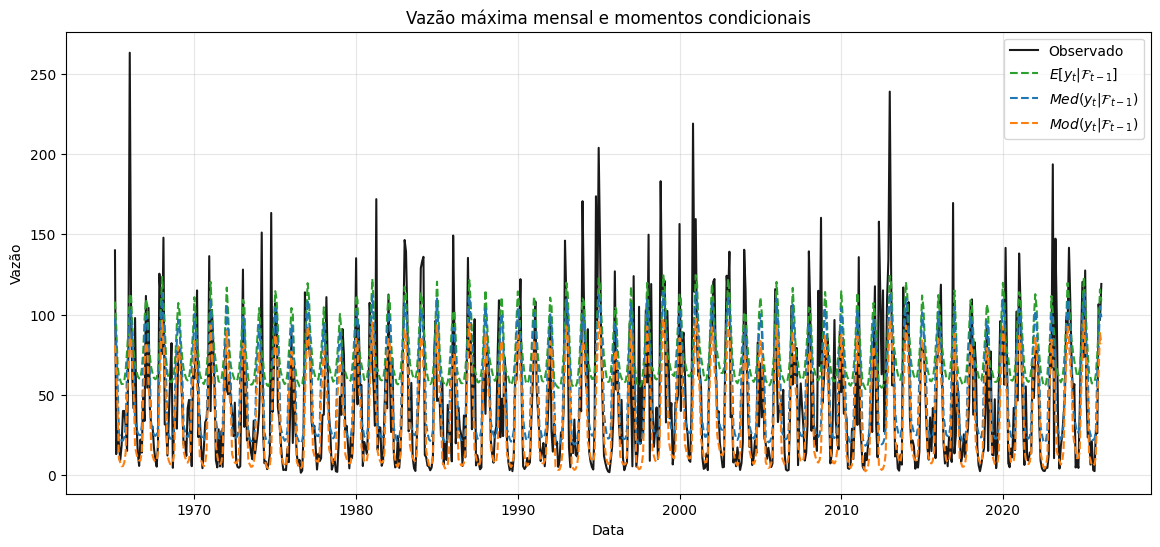

In [140]:
plt.figure(figsize=(14, 6))

plt.plot(series.index, series, label="Observado", color='black', alpha=0.9)
# plt.plot(series.index, eta_t, label=r"$\mu_{t|t-1} + \gamma_t$")
plt.plot(series.index, mean_cond, label=r"$E[y_t|\mathcal{F}_{t-1}]$", color='C2', linestyle='--')
plt.plot(series.index, median_cond, label=r"$Med(y_t|\mathcal{F}_{t-1})$", linestyle='--')
plt.plot(series.index, mode_cond, label=r"$Mod(y_t|\mathcal{F}_{t-1})$", linestyle='--')

plt.xlabel("Data")
plt.ylabel("Vazão")
plt.title("Vazão máxima mensal e momentos condicionais")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

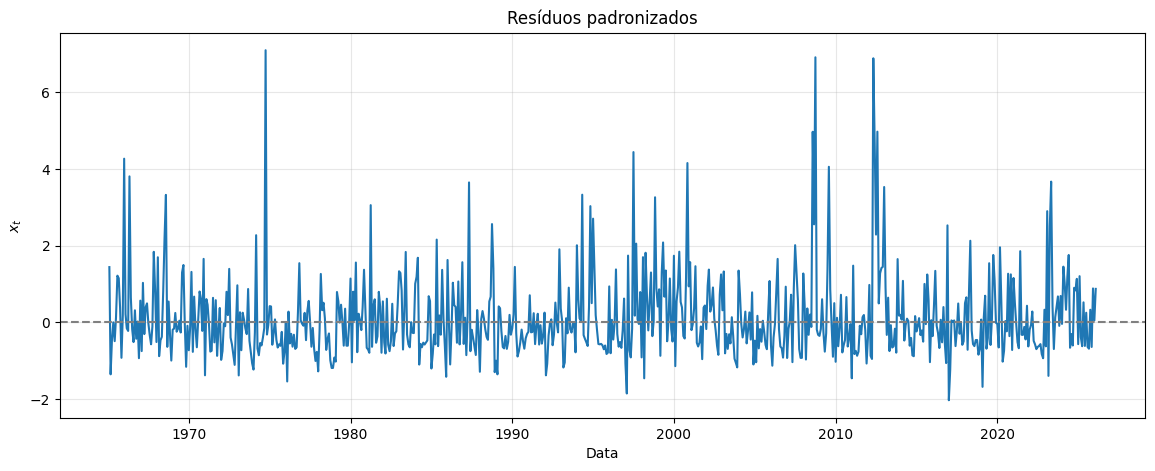

In [45]:
plt.figure(figsize=(14, 5))

plt.plot(series.index, x)
plt.axhline(0, linestyle="--", color='gray')

plt.xlabel("Data")
plt.ylabel(r"$x_t$")
plt.title("Resíduos padronizados")
plt.grid(alpha=0.3)

plt.show()

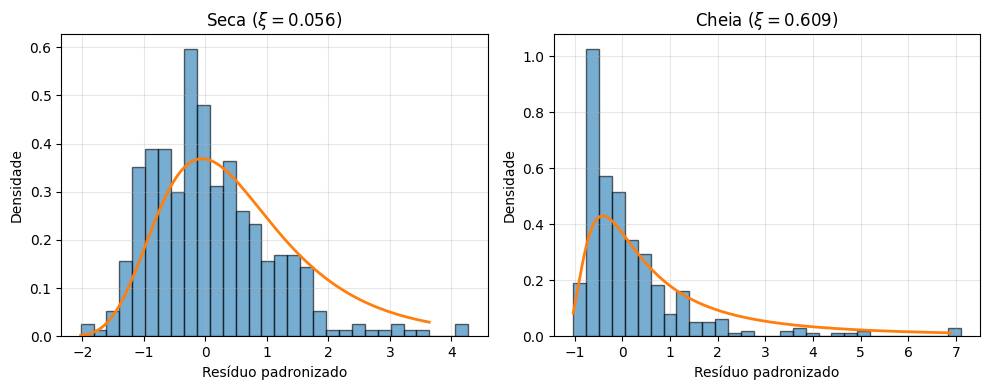

In [44]:
# Separar os resíduos por regime
regimes = [
    (x[dummy == 0], xi_seca_hat, "Seca"),
    (x[dummy == 1], xi_cheia_hat, "Cheia")
]

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (x_regime, xi_hat, nome) in zip(axes, regimes):
    # Grade da densidade teórica
    x_grid = np.linspace(np.min(x_regime), np.percentile(x_regime, 99.5), 500)

    # Histograma dos resíduos padronizados
    ax.hist(x_regime, bins=30, density=True, alpha=0.6, edgecolor="black")
    pdf = genextreme.pdf(x_grid, c=-xi_hat, loc=0, scale=1)
    ax.plot(x_grid, pdf, linewidth=2) # Densidade teórica

    ax.set_title(f"{nome} ($\\xi={xi_hat:.3f}$)")
    ax.set_xlabel("Resíduo padronizado")
    ax.set_ylabel("Densidade")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

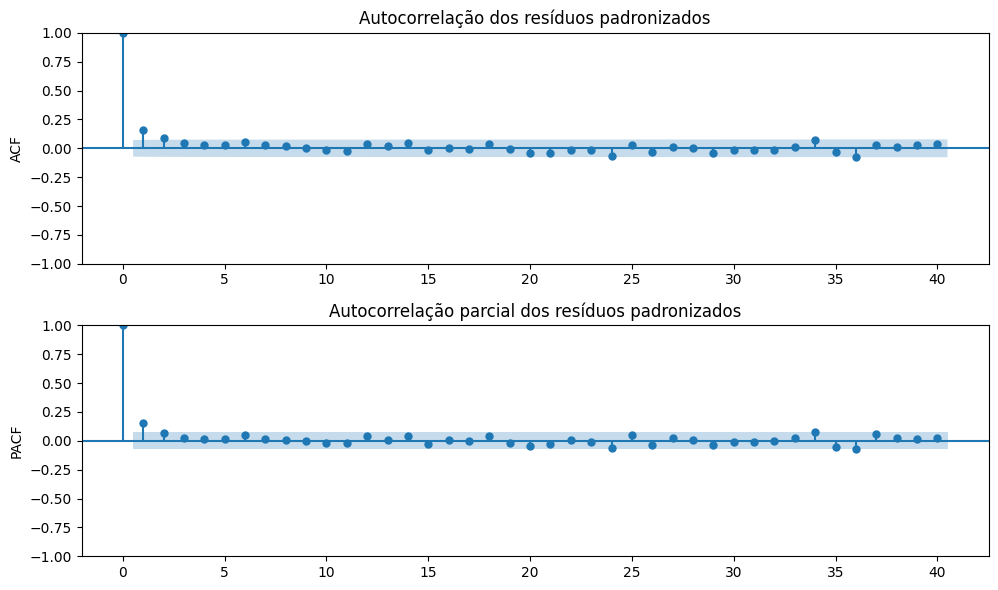

In [46]:
fig, ax = plt.subplots(2, 1, figsize=(10, 6))

plot_acf(x, lags=40, ax=ax[0])
plot_pacf(x, lags=40, ax=ax[1])
ax[0].set_title("Autocorrelação dos resíduos padronizados")
ax[0].set_ylabel("ACF")
ax[1].set_title("Autocorrelação parcial dos resíduos padronizados")
ax[1].set_ylabel("PACF")

plt.tight_layout()
plt.show()

## Score

In [19]:
def resumo(v):
    v = np.asarray(v, dtype=float)
    v = v[np.isfinite(v)]

    if len(v) == 0:
        return pd.Series({
            "n": 0, "Média": np.nan, "DP": np.nan,
            "Min": np.nan, "P1": np.nan, "P5": np.nan,
            "P95": np.nan, "P99": np.nan, "Max": np.nan
        })

    return pd.Series({
        "n": len(v),
        "Média": np.mean(v),
        "Desvio": np.std(v, ddof=1) if len(v) > 1 else np.nan,
        "Min": np.min(v),
        "Q1": np.quantile(v, 0.01),
        "Q5": np.quantile(v, 0.05),
        "Q95": np.quantile(v, 0.95),
        "Q99": np.quantile(v, 0.99),
        "Max": np.max(v)
    })

In [109]:
T = len(y)
t = np.arange(T)

df = pd.DataFrame({"t": t, "y": y, "x": x, "xi": xi_t, "s_composite": s})
df["c"] = np.nan
df["d"] = np.nan
df["regiao"] = "Gumbel"
df["score_modificado"] = False
df["estacao"] = np.where(dummy == 1, "Cheia", "Seca")

for xi_value in np.unique(xi_t):

    mask = np.isclose(xi_t, xi_value, rtol=0, atol=1e-12)
    if abs(xi_value) < 1e-6:
        continue
        
    c, d = harvey._find_c(xi_value), harvey._find_d(xi_value)
    df.loc[mask, "c"] = c
    df.loc[mask, "d"] = d

    lower = mask & (x <= c)
    middle = mask & (x > c) & (x <= d)
    upper = mask & (x > d)

    # A modificação ocorre fora da região intermediária
    df.loc[lower, "regiao"] = "Inferior"
    df.loc[middle, "regiao"] = "Intermediária"
    df.loc[upper, "regiao"] = "Superior"
    df.loc[lower | upper, "score_modificado"] = True

In [110]:
I_t = harvey.fisher_information(xi_t, varphi_t)

score_bruto = harvey.score(y, xi_t, mu_filtered, gamma_t, varphi_t)

score_original = np.asarray(score_bruto).reshape(-1) / np.asarray(I_t).reshape(-1)

df["s_original"] = score_original
df["diferenca"] = df["s_composite"] - df["s_original"]

df["ds_dmu"] = -harvey.score_derivative(x, xi_t)
df.loc[df.regiao=='Inferior','ds_dmu'] = -1
df.loc[df.regiao=='Superior','ds_dmu'] = 0
df.head(3)

,t,y,x,xi,s_composite,c,d,regiao,score_modificado,estacao,s_original,diferenca,ds_dmu
date,,,,,,,,,,,,,
1965-01-31,0,139.979,1.438260,0.052998,28.352384,-0.046219,3.178497,Intermediária,False,Seca,28.352384,0.000000,-0.170257
1965-02-28,1,13.017,-1.364594,0.052998,-52.502196,-0.046219,3.178497,Inferior,True,Seca,-125.740192,73.237996,-1.000000
1965-03-31,2,29.046,-0.396274,0.052998,-13.782708,-0.046219,3.178497,Inferior,True,Seca,-17.062682,3.279974,-1.000000


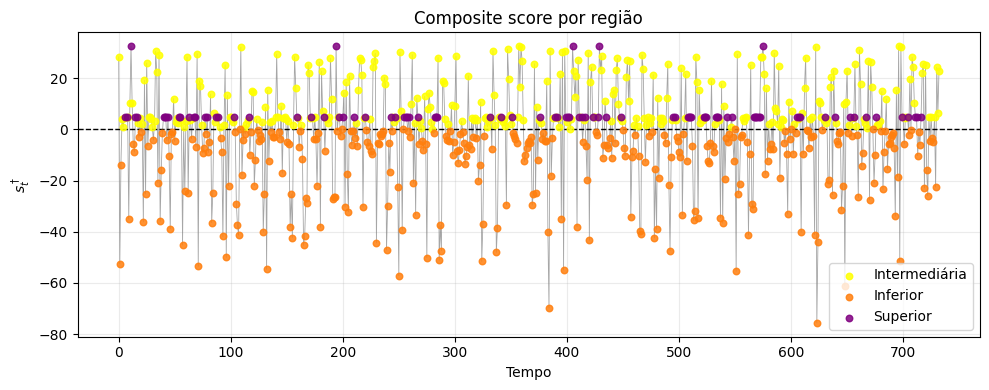

In [111]:
cores = {
    "Inferior": "tab:orange",
    "Intermediária": "yellow",
    "Superior": "purple",
    "Gumbel": "tab:blue"
}

fig, ax = plt.subplots(figsize=(10, 4))

ax.plot(np.arange(len(s)), s, linewidth=0.6, color='gray', alpha=0.7)
for regiao, grupo in df.groupby("regiao", sort=False):
    ax.scatter(grupo["t"], grupo["s_composite"], s=22, color=cores[regiao], label=regiao, alpha=0.85, zorder=3)

ax.axhline(0, color="black", linestyle="--", linewidth=1)
ax.set(title="Composite score por região", xlabel="Tempo", ylabel=r"$s_t^\dagger$")
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

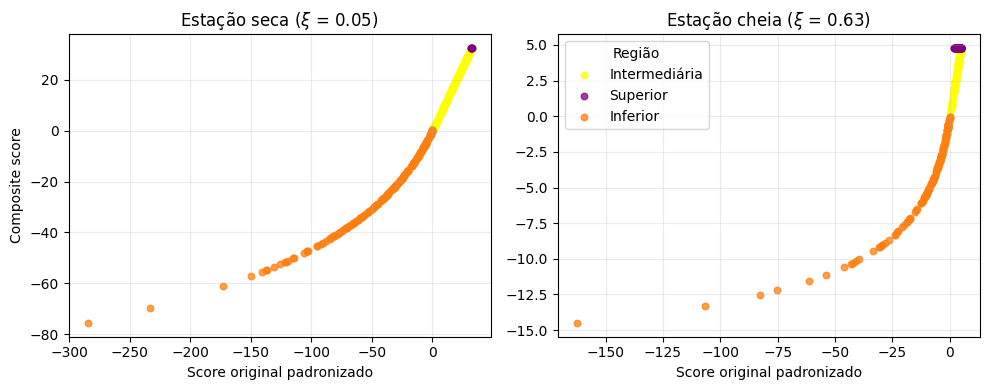

In [112]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, estacao in zip(axes, ["Seca", "Cheia"]):
    df_estacao = df[df["estacao"] == estacao]
    xi = df_estacao['xi'].iloc[0]

    for regiao, grupo in df_estacao.groupby("regiao", sort=False):
        ax.scatter(grupo["s_original"], grupo["s_composite"], s=22, color=cores[regiao], label=regiao, alpha=0.75)

    ax.set(title=f"Estação {estacao.lower()} ($\\xi$ = {xi:.2f})", xlabel="Score original padronizado")
    ax.grid(alpha=0.25)

axes[0].set_ylabel("Composite score")
axes[1].legend(title="Região")

plt.tight_layout()
plt.show()

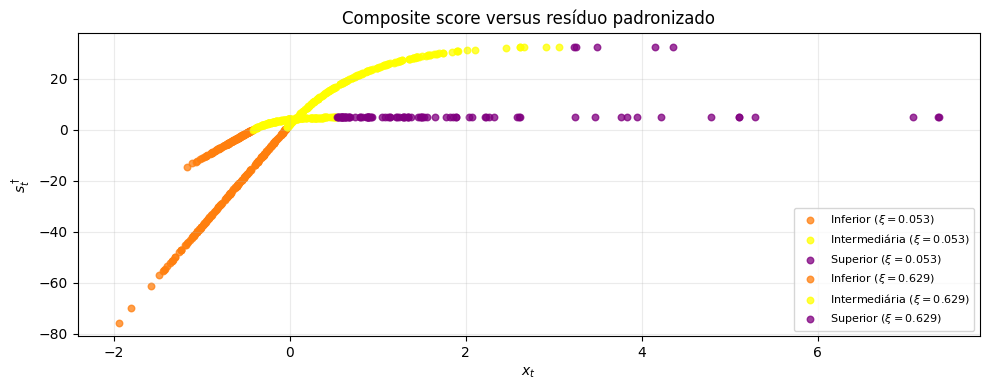

In [113]:
fig, ax = plt.subplots(figsize=(10, 4))

for xi_value in np.unique(xi_t):

    mask = np.isclose(xi_t, xi_value, rtol=0, atol=1e-12)
    if abs(xi_value) < 1e-6:
        regiao = df.loc[mask, "regiao"]
        ax.scatter(x[mask], s[mask], color=cores["Gumbel"], s=18, alpha=0.6, label="Gumbel")
        continue

    for nome in ["Inferior", "Intermediária", "Superior"]:
        m = mask & (df["regiao"].to_numpy() == nome)
        ax.scatter(x[m], s[m], color=cores[nome], s=22, alpha=0.75, label=f"{nome} ($\\xi={xi_value:.3f}$)")

    # c = harvey._find_c(xi_value)
    # d = harvey._find_d(xi_value)
    # ax.axvline(c, color="gray", linestyle=":", alpha=0.6)
    # ax.axvline(d, color="gray", linestyle="--", alpha=0.6)

ax.set(title="Composite score versus resíduo padronizado", xlabel=r"$x_t$", ylabel=r"$s_t^\dagger$")
ax.grid(alpha=0.25)

# Remove rótulos duplicados da legenda
handles, labels = ax.get_legend_handles_labels()
by_label = dict(zip(labels, handles))
ax.legend(by_label.values(), by_label.keys(), fontsize=8)

plt.tight_layout()
plt.show()

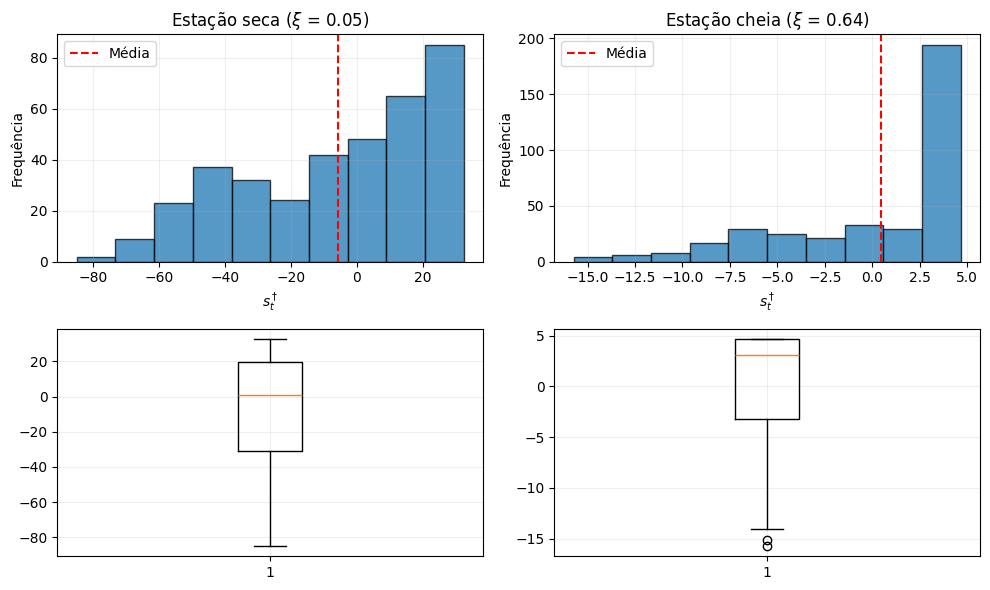

In [92]:
fig, axes = plt.subplots(2, 2, figsize=(10, 6))

for j, estacao in enumerate(["Seca", "Cheia"]):
    valores = df.loc[df["estacao"] == estacao, "s_composite"].dropna()
    xi = df.loc[df["estacao"] == estacao, 'xi'].iloc[0]

    axes[0, j].hist(valores, bins="auto", edgecolor="black", alpha=0.75)
    axes[0, j].axvline(valores.mean(), color="red", linestyle="--", label="Média")
    axes[0, j].set(title=f"Estação {estacao.lower()} ($\\xi$ = {xi:.2f})", xlabel=r"$s_t^\dagger$", ylabel="Frequência")
    axes[0, j].legend()
    axes[0, j].grid(alpha=0.2)
    
    axes[1, j].boxplot(valores, vert=True)
    # axes[1, j].set(title=f"Boxplot — {estacao.lower()}", ylabel=r"$s_t^\dagger$")
    axes[1, j].grid(alpha=0.2)

plt.tight_layout()
plt.show()

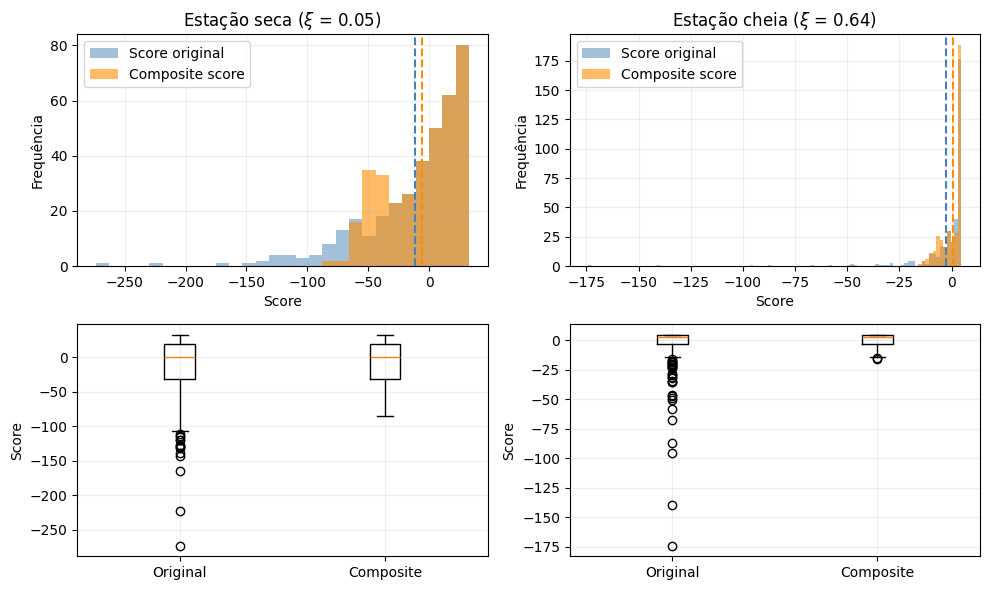

In [93]:
fig, axes = plt.subplots(2, 2, figsize=(10, 6))

for j, estacao in enumerate(["Seca", "Cheia"]):
    df_estacao = df[df["estacao"] == estacao]
    composite = df_estacao["s_composite"].dropna()
    original = df_estacao["s_original"].dropna()
    xi = df_estacao["xi"].iloc[0]

    # Histograma sobreposto
    bins = np.histogram_bin_edges(
        np.concatenate([composite.to_numpy(), original.to_numpy()]),
        bins="auto"
    )
    axes[0, j].hist(original, bins=bins, color="steelblue", alpha=0.5, label="Score original")
    axes[0, j].hist(composite, bins=bins, color="darkorange", alpha=0.6, label="Composite score")
    axes[0, j].axvline(original.mean(), color="steelblue", linestyle="--")
    axes[0, j].axvline(composite.mean(), color="darkorange", linestyle="--")
    axes[0, j].set(title=f"Estação {estacao.lower()} ($\\xi$ = {xi:.2f})", xlabel="Score", ylabel="Frequência")
    axes[0, j].legend()
    axes[0, j].grid(alpha=0.2)

    # Boxplots lado a lado
    axes[1, j].boxplot(
        [original, composite],
        tick_labels=["Original", "Composite"],
        showfliers=True
    )
    axes[1, j].set_ylabel("Score")
    axes[1, j].grid(alpha=0.2)

plt.tight_layout()
plt.show()

In [122]:
print("\nEstatísticas gerais:")
resumo(df["s_composite"]).to_frame("Composite score").round(2).T


Estatísticas gerais:


,n,Média,Desvio,Min,Q1,Q5,Q95,Q99,Max
Composite score,733.0,-1.14,18.17,-75.85,-53.39,-39.08,28.11,32.3,32.53


In [123]:
frequencias = (
    df.groupby("estacao")
      .agg(
          n=("s_composite", "size"),
          media=("s_composite", "mean"),
          minimo=("s_composite", "min"),
          maximo=("s_composite", "max")
      )
)

frequencias["proporcao_%"] = 100 * frequencias["n"] / len(df)
print(
    "\nProporção total com score modificado:",
    round(100 * df["score_modificado"].mean(), 2), "%"
)
frequencias.round(2)


Proporção total com score modificado: 57.03 %


,n,media,minimo,maximo,proporcao_%
estacao,,,,,
Cheia,366,0.74,-14.51,4.77,49.93
Seca,367,-3.02,-75.85,32.53,50.07


## Derivada

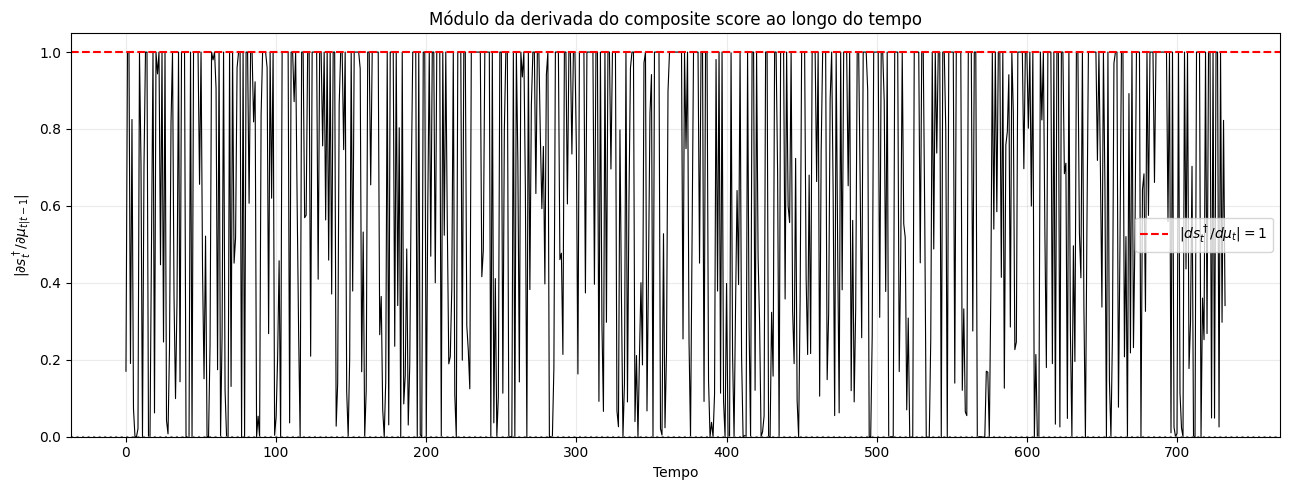

In [114]:
fig, ax = plt.subplots(figsize=(13, 5))

ax.plot(df["t"], df["ds_dmu"].abs(), linewidth=0.8, color="black")
ax.axhline(1, color="red", linestyle="--", label=r"$|ds_t^\dagger/d\mu_t|=1$")
ax.axhline(0, color="gray", linestyle=":")

ax.set_xlabel("Tempo")
ax.set_ylabel(r"$|\partial s_t^\dagger/\partial\mu_{t|t-1}|$")
ax.set_title("Módulo da derivada do composite score ao longo do tempo")
ax.set_ylim(bottom=0)
ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

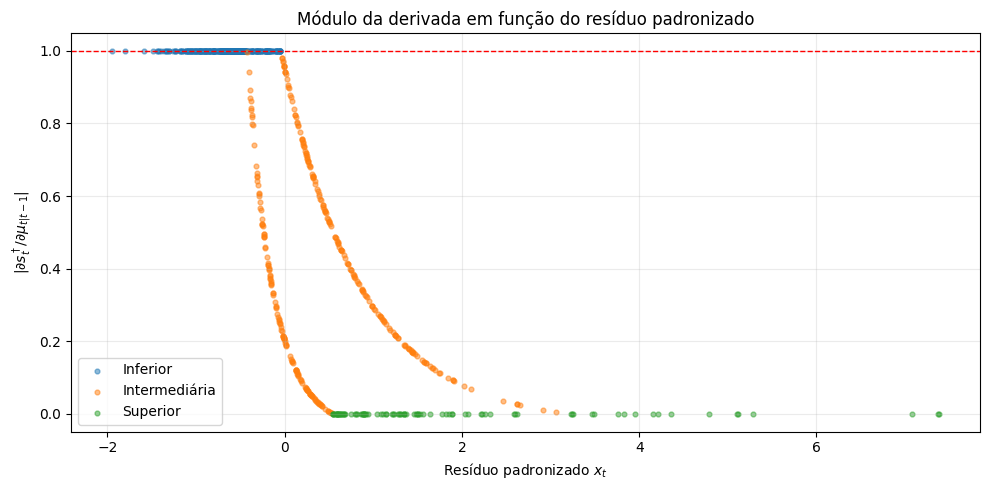

In [115]:
fig, ax = plt.subplots(figsize=(10, 5))

colors = {
    "Inferior": "tab:blue",
    "Intermediária": "tab:orange",
    "Superior": "tab:green"
}

for region, color in colors.items():
    mask = df["regiao"] == region
    ax.scatter(df.loc[mask, "x"], df.loc[mask, "ds_dmu"].abs(), s=12, alpha=0.5, label=region, color=color)

ax.axhline(1, color="red", linestyle="--", linewidth=1)
ax.set_xlabel(r"Resíduo padronizado $x_t$")
ax.set_ylabel(r"$|\partial s_t^\dagger/\partial\mu_{t|t-1}|$")
ax.set_title("Módulo da derivada em função do resíduo padronizado")
ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()